# COMP813 — Cross-Dataset Generalisation of NLP Models for Phishing Email Detection

## Cross-Dataset Evaluation: Enron → CEAS-08

### Research Question

How well do NLP-based phishing email detection models trained on
the Enron email corpus generalise to a previously unseen CEAS-08
email corpus?

### Experimental Design

All three models were trained exclusively using the Enron dataset.

The models are evaluated on CEAS-08 without retraining, fine-tuning,
or fitting feature representations using CEAS-08.

### Models

1. TF-IDF + Logistic Regression
2. TF-IDF + Linear SVM
3. BiLSTM

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

### Key Principle

CEAS-08 is treated as an external, unseen dataset. It is not used
for model training, vocabulary construction, TF-IDF fitting, or
model selection.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import re
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

PyTorch version: 2.11.0+cu128
Device: cuda


## 1. Load CEAS-08

CEAS-08 is used as the external evaluation dataset.

No model training, TF-IDF fitting, vocabulary construction, or
hyperparameter tuning is performed using this dataset.

In [3]:
ceas = pd.read_csv("ceas08_clean.csv")

print("CEAS-08 shape:", ceas.shape)
print()
print("Label distribution:")
print(ceas["label"].value_counts())

CEAS-08 shape: (38964, 2)

Label distribution:
label
1    21674
0    17290
Name: count, dtype: int64


In [4]:
ceas.head()

,text,label
0,subject: never agree to be a loser body: buck ...,1
1,subject: befriend jenna jameson body: upgrade ...,1
2,subject: cnn.com daily top 10 body: >+=+=+=+=+...,1
3,subject: re: svn commit: r619753 - in /spamass...,0
4,subject: specialpricespharmmoreinfo body: welc...,1


In [5]:
print(ceas["text"].isna().sum())
print(ceas["label"].isna().sum())

0
0


In [6]:
X_ceas = ceas["text"].astype(str)
y_ceas = ceas["label"].values

print("CEAS emails:", len(X_ceas))
print("CEAS labels:", len(y_ceas))

CEAS emails: 38964
CEAS labels: 38964


## 2. Logistic Regression — Cross-Dataset Evaluation

The Logistic Regression model and TF-IDF vectorizer trained on
Enron are loaded.

The saved TF-IDF vectorizer is used to transform CEAS-08.
It is not refitted on CEAS-08.

In [7]:
lr_model = joblib.load(
    "logistic_regression_enron.pkl"
)

lr_tfidf = joblib.load(
    "tfidf_vectorizer.pkl"
)

print("Logistic Regression model loaded.")
print("TF-IDF vocabulary size:", len(lr_tfidf.vocabulary_))

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Logistic Regression model loaded.
TF-IDF vocabulary size: 100000


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [8]:
X_ceas_lr = lr_tfidf.transform(X_ceas)

print("CEAS TF-IDF matrix:", X_ceas_lr.shape)

CEAS TF-IDF matrix: (38964, 100000)


## 3. Logistic Regression — CEAS-08 Evaluation

The Logistic Regression model trained exclusively on Enron is
evaluated directly on CEAS-08.

The model and TF-IDF representation are frozen. No retraining,
fine-tuning, or feature fitting is performed using CEAS-08.

In [9]:
lr_ceas_pred = lr_model.predict(X_ceas_lr)

lr_ceas_accuracy = accuracy_score(
    y_ceas,
    lr_ceas_pred
)

lr_ceas_precision = precision_score(
    y_ceas,
    lr_ceas_pred
)

lr_ceas_recall = recall_score(
    y_ceas,
    lr_ceas_pred
)

lr_ceas_f1 = f1_score(
    y_ceas,
    lr_ceas_pred
)

print("LOGISTIC REGRESSION — CEAS-08")
print("=" * 50)

print(f"Accuracy : {lr_ceas_accuracy:.4f}")
print(f"Precision: {lr_ceas_precision:.4f}")
print(f"Recall   : {lr_ceas_recall:.4f}")
print(f"F1 Score : {lr_ceas_f1:.4f}")

LOGISTIC REGRESSION — CEAS-08
Accuracy : 0.6674
Precision: 0.6262
Recall   : 0.9978
F1 Score : 0.7695


In [10]:
print(
    classification_report(
        y_ceas,
        lr_ceas_pred,
        target_names=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )
)

               precision    recall  f1-score   support

   Legitimate       0.99      0.25      0.40     17290
Phishing/Spam       0.63      1.00      0.77     21674

     accuracy                           0.67     38964
    macro avg       0.81      0.63      0.59     38964
 weighted avg       0.79      0.67      0.61     38964



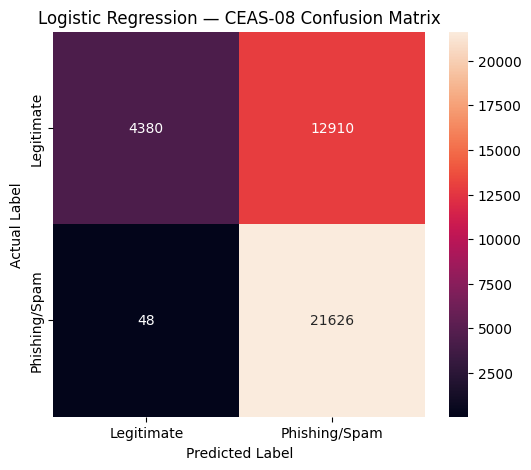

In [11]:
cm_lr_ceas = confusion_matrix(
    y_ceas,
    lr_ceas_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr_ceas,
    annot=True,
    fmt="d",
    xticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression — CEAS-08 Confusion Matrix")

plt.show()

## 4. Linear SVM — Cross-Dataset Evaluation

The Linear SVM and its TF-IDF vectorizer trained exclusively on
Enron are loaded.

The saved TF-IDF vectorizer is used to transform CEAS-08 without
refitting.

In [12]:
svm_model = joblib.load(
    "svm_enron.pkl"
)

svm_tfidf = joblib.load(
    "tfidf_svm_vectorizer.pkl"
)

print("SVM model loaded.")
print("TF-IDF vocabulary size:", len(svm_tfidf.vocabulary_))

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LinearSVC from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


SVM model loaded.
TF-IDF vocabulary size: 100000


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [13]:
X_ceas_svm = svm_tfidf.transform(X_ceas)

print("CEAS TF-IDF matrix:", X_ceas_svm.shape)

CEAS TF-IDF matrix: (38964, 100000)


In [14]:
svm_ceas_pred = svm_model.predict(X_ceas_svm)

svm_ceas_accuracy = accuracy_score(
    y_ceas,
    svm_ceas_pred
)

svm_ceas_precision = precision_score(
    y_ceas,
    svm_ceas_pred
)

svm_ceas_recall = recall_score(
    y_ceas,
    svm_ceas_pred
)

svm_ceas_f1 = f1_score(
    y_ceas,
    svm_ceas_pred
)

print("LINEAR SVM — CEAS-08")
print("=" * 50)

print(f"Accuracy : {svm_ceas_accuracy:.4f}")
print(f"Precision: {svm_ceas_precision:.4f}")
print(f"Recall   : {svm_ceas_recall:.4f}")
print(f"F1 Score : {svm_ceas_f1:.4f}")

LINEAR SVM — CEAS-08
Accuracy : 0.6877
Precision: 0.6413
Recall   : 0.9956
F1 Score : 0.7801


In [15]:
print(
    classification_report(
        y_ceas,
        svm_ceas_pred,
        target_names=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )
)

               precision    recall  f1-score   support

   Legitimate       0.98      0.30      0.46     17290
Phishing/Spam       0.64      1.00      0.78     21674

     accuracy                           0.69     38964
    macro avg       0.81      0.65      0.62     38964
 weighted avg       0.79      0.69      0.64     38964



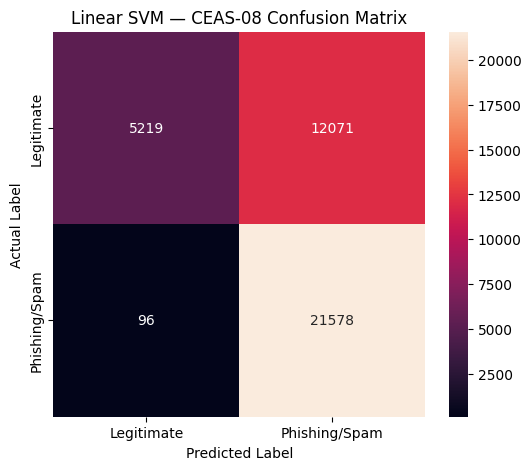

In [16]:
cm_svm_ceas = confusion_matrix(
    y_ceas,
    svm_ceas_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm_ceas,
    annot=True,
    fmt="d",
    xticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Linear SVM — CEAS-08 Confusion Matrix")

plt.show()

In [17]:
with open(
    "bilstm_vocabulary.json",
    "r"
) as f:
    word_to_index = json.load(f)

# JSON stores dictionary keys as strings, so convert them back
# to integer indices if needed later.
word_to_index = {
    str(word): int(index)
    for word, index in word_to_index.items()
}

print("BiLSTM vocabulary size:", len(word_to_index))

BiLSTM vocabulary size: 50000


In [18]:
MAX_SEQUENCE_LENGTH = 500

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"


def tokenize_text(text):
    return re.findall(r"\b\w+\b", text.lower())


def text_to_sequence(text, word_to_index, max_length):

    tokens = tokenize_text(text)

    sequence = [
        word_to_index.get(
            token,
            word_to_index[UNK_TOKEN]
        )
        for token in tokens
    ]

    sequence = sequence[:max_length]

    if len(sequence) < max_length:
        sequence += [
            word_to_index[PAD_TOKEN]
        ] * (max_length - len(sequence))

    return sequence


X_ceas_bilstm = np.array([
    text_to_sequence(
        text,
        word_to_index,
        MAX_SEQUENCE_LENGTH
    )
    for text in X_ceas
])

print("CEAS BiLSTM sequences:", X_ceas_bilstm.shape)

CEAS BiLSTM sequences: (38964, 500)


## 5. BiLSTM — Cross-Dataset Evaluation

The BiLSTM architecture used during Enron training is recreated and
the saved Enron model weights are loaded.

No parameters are retrained or updated using CEAS-08.

In [19]:
class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        dropout=0.3
    ):
        super(BiLSTMClassifier, self).__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):

        embedded = self.embedding(x)

        _, (hidden, _) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        output = self.dropout(combined_hidden)

        output = self.fc(output)

        return output.squeeze(1)

In [20]:
bilstm_checkpoint = torch.load(
    "bilstm_enron.pt",
    map_location=device
)

bilstm_model = BiLSTMClassifier(
    vocab_size=bilstm_checkpoint["vocab_size"],
    embedding_dim=bilstm_checkpoint["embedding_dim"],
    hidden_dim=bilstm_checkpoint["hidden_dim"],
    dropout=bilstm_checkpoint["dropout"]
)

bilstm_model.load_state_dict(
    bilstm_checkpoint["model_state_dict"]
)

bilstm_model = bilstm_model.to(device)

bilstm_model.eval()

print("BiLSTM model loaded successfully.")
print("Vocabulary size:", bilstm_checkpoint["vocab_size"])
print("Sequence length:", bilstm_checkpoint["max_sequence_length"])
print("Device:", device)

BiLSTM model loaded successfully.
Vocabulary size: 50000
Sequence length: 500
Device: cuda


In [21]:
ceas_sequences_tensor = torch.tensor(
    X_ceas_bilstm,
    dtype=torch.long
)

ceas_labels_tensor = torch.tensor(
    y_ceas,
    dtype=torch.float32
)

ceas_bilstm_dataset = torch.utils.data.TensorDataset(
    ceas_sequences_tensor,
    ceas_labels_tensor
)

ceas_bilstm_loader = torch.utils.data.DataLoader(
    ceas_bilstm_dataset,
    batch_size=64,
    shuffle=False
)

print("CEAS batches:", len(ceas_bilstm_loader))

CEAS batches: 609


## 6. BiLSTM — CEAS-08 Evaluation

The frozen BiLSTM trained on Enron is evaluated directly on CEAS-08.

The Enron-trained vocabulary, embedding weights, LSTM parameters,
and classification layer are unchanged.

No CEAS-08 data is used to update model parameters.

In [22]:
bilstm_ceas_predictions = []
bilstm_ceas_labels = []

bilstm_model.eval()

with torch.no_grad():

    for sequences, labels in ceas_bilstm_loader:

        sequences = sequences.to(device)

        outputs = bilstm_model(sequences)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        bilstm_ceas_predictions.extend(
            predictions.cpu().numpy()
        )

        bilstm_ceas_labels.extend(
            labels.numpy()
        )


bilstm_ceas_predictions = np.array(
    bilstm_ceas_predictions
)

bilstm_ceas_labels = np.array(
    bilstm_ceas_labels
)

In [23]:
bilstm_ceas_accuracy = accuracy_score(
    bilstm_ceas_labels,
    bilstm_ceas_predictions
)

bilstm_ceas_precision = precision_score(
    bilstm_ceas_labels,
    bilstm_ceas_predictions,
    zero_division=0
)

bilstm_ceas_recall = recall_score(
    bilstm_ceas_labels,
    bilstm_ceas_predictions,
    zero_division=0
)

bilstm_ceas_f1 = f1_score(
    bilstm_ceas_labels,
    bilstm_ceas_predictions,
    zero_division=0
)

print("BiLSTM — CEAS-08")
print("=" * 50)

print(f"Accuracy : {bilstm_ceas_accuracy:.4f}")
print(f"Precision: {bilstm_ceas_precision:.4f}")
print(f"Recall   : {bilstm_ceas_recall:.4f}")
print(f"F1 Score : {bilstm_ceas_f1:.4f}")

BiLSTM — CEAS-08
Accuracy : 0.5654
Precision: 0.5733
Recall   : 0.8554
F1 Score : 0.6865


In [24]:
print(
    classification_report(
        bilstm_ceas_labels,
        bilstm_ceas_predictions,
        target_names=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )
)

               precision    recall  f1-score   support

   Legitimate       0.53      0.20      0.29     17290
Phishing/Spam       0.57      0.86      0.69     21674

     accuracy                           0.57     38964
    macro avg       0.55      0.53      0.49     38964
 weighted avg       0.55      0.57      0.51     38964



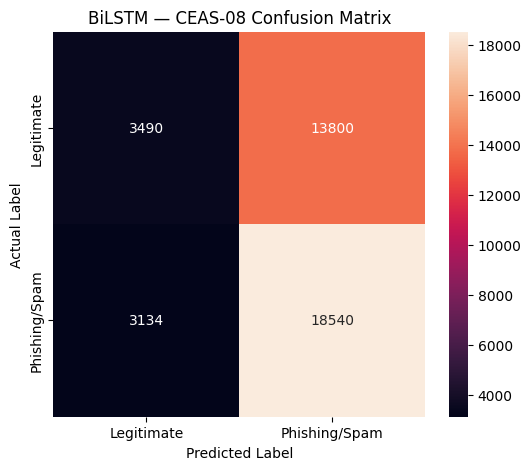

In [25]:
cm_bilstm_ceas = confusion_matrix(
    bilstm_ceas_labels,
    bilstm_ceas_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_bilstm_ceas,
    annot=True,
    fmt="d",
    xticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("BiLSTM — CEAS-08 Confusion Matrix")

plt.show()

## 7. Cross-Dataset Results

In [26]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "BiLSTM"
    ],

    "Enron Accuracy": [
        0.9855,
        0.9907,
        0.9783
    ],

    "Enron F1": [
        0.9849,
        0.9902,
        0.9771
    ],

    "CEAS-08 Accuracy": [
        lr_ceas_accuracy,
        svm_ceas_accuracy,
        bilstm_ceas_accuracy
    ],

    "CEAS-08 F1": [
        lr_ceas_f1,
        svm_ceas_f1,
        bilstm_ceas_f1
    ]
})

results["F1 Drop"] = (
    results["Enron F1"] -
    results["CEAS-08 F1"]
)

results

,Model,Enron Accuracy,Enron F1,CEAS-08 Accuracy,CEAS-08 F1,F1 Drop
0,Logistic Regression,0.9855,0.9849,0.667437,0.769472,0.215428
1,Linear SVM,0.9907,0.9902,0.687737,0.780073,0.210127
2,BiLSTM,0.9783,0.9771,0.565394,0.686489,0.290611


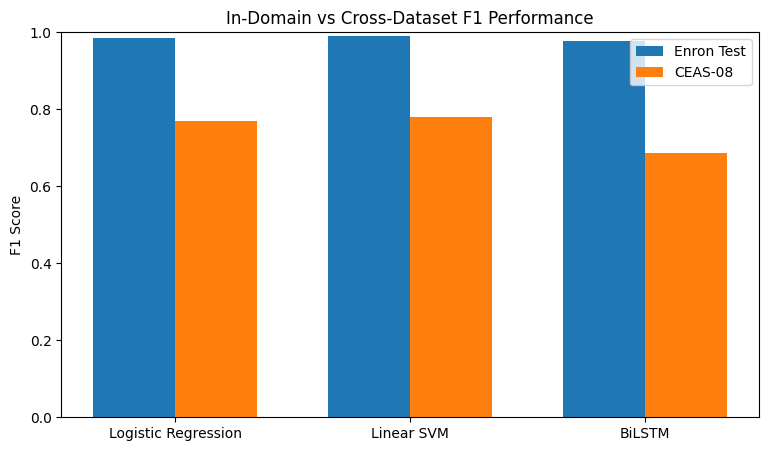

In [27]:
plt.figure(figsize=(9, 5))

x = np.arange(len(results))
width = 0.35

plt.bar(
    x - width/2,
    results["Enron F1"],
    width,
    label="Enron Test"
)

plt.bar(
    x + width/2,
    results["CEAS-08 F1"],
    width,
    label="CEAS-08"
)

plt.xticks(
    x,
    results["Model"]
)

plt.ylabel("F1 Score")
plt.title("In-Domain vs Cross-Dataset F1 Performance")
plt.legend()
plt.ylim(0, 1)

plt.show()

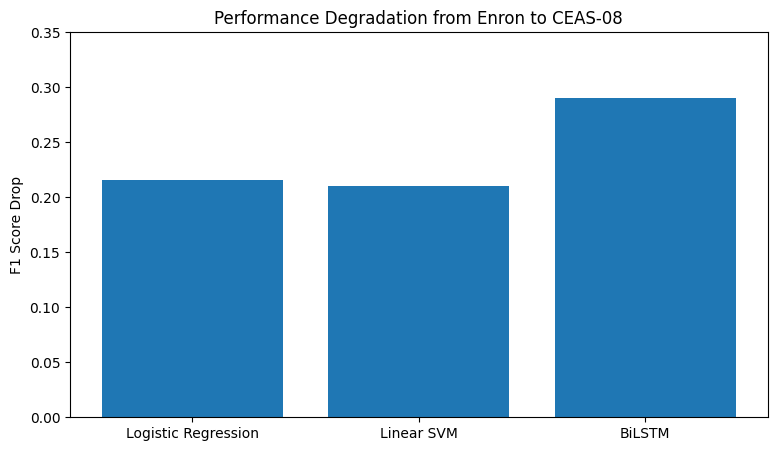

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["F1 Drop"]
)

plt.ylabel("F1 Score Drop")
plt.title("Performance Degradation from Enron to CEAS-08")

plt.ylim(0, 0.35)

plt.show()

## 8. Cross-Dataset Generalisation Analysis

All three models achieved high performance on the held-out Enron
test set but experienced substantial performance degradation when
evaluated on the unseen CEAS-08 dataset.

Logistic Regression decreased from an Enron F1-score of 98.49% to
76.95% on CEAS-08. Linear SVM decreased from 99.02% to 78.01%,
while the BiLSTM decreased from 97.71% to 68.65%.

The confusion matrices indicate that the main source of degradation
was the increased number of legitimate CEAS-08 emails classified as
phishing/spam. At the same time, all three models retained relatively
high recall for the phishing/spam class.

These results demonstrate that strong in-domain performance does not
necessarily translate into equivalent performance on a different
email corpus. The results suggest that differences between datasets,
including differences in vocabulary, email characteristics and
distribution, can affect cross-dataset generalisation.

The experiment therefore highlights the importance of evaluating
phishing detection models on external datasets rather than relying
only on random train/test splits from the same corpus.

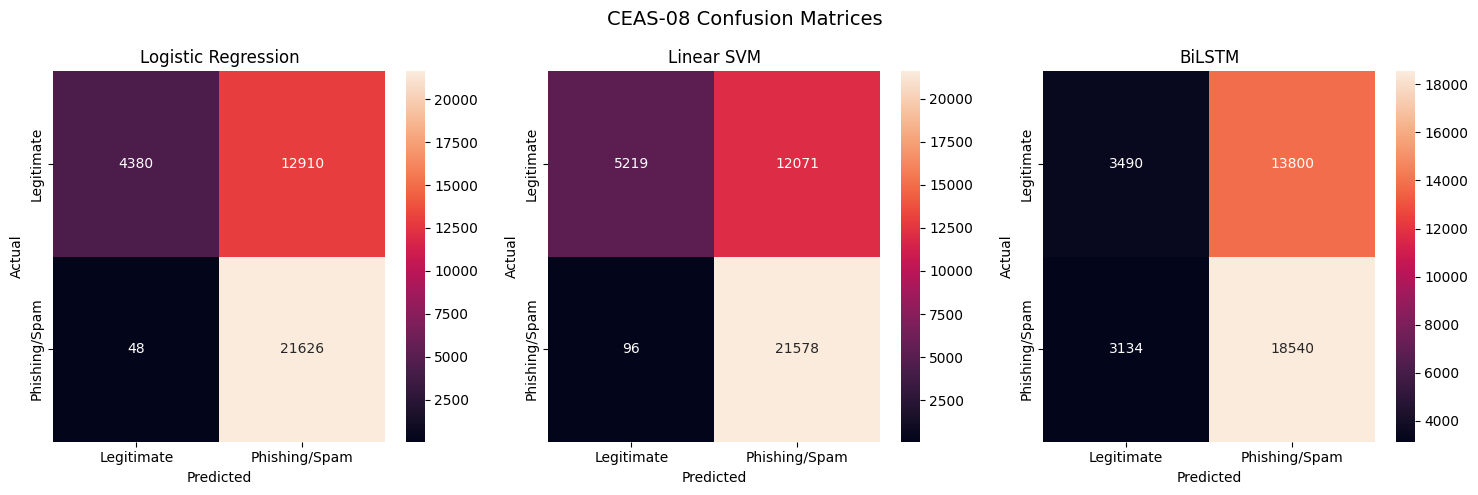

In [33]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

confusion_matrices = [
    cm_lr_ceas,
    cm_svm_ceas,
    cm_bilstm_ceas
]

model_names = [
    "Logistic Regression",
    "Linear SVM",
    "BiLSTM"
]

for ax, cm, name in zip(
    axes,
    confusion_matrices,
    model_names
):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        ax=ax,
        xticklabels=[
            "Legitimate",
            "Phishing/Spam"
        ],
        yticklabels=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "CEAS-08 Confusion Matrices",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [34]:
results_display.to_csv(
    "cross_dataset_results.csv",
    index=False
)

print(
    "Cross-dataset results saved successfully."
)

Cross-dataset results saved successfully.


## 8. Findings from Cross-Dataset Evaluation

All three models achieved substantially higher performance on the
held-out Enron test set than on the unseen CEAS-08 dataset.

The Logistic Regression model decreased from an Enron F1-score of
98.49% to 76.95% on CEAS-08. The Linear SVM decreased from 99.02%
to 78.01%, while the BiLSTM decreased from 97.71% to 68.65%.

The confusion matrices show a common pattern across the models:
large numbers of legitimate CEAS-08 emails were classified as
phishing/spam. At the same time, phishing/spam recall remained
relatively high.

These results indicate substantial cross-dataset performance
degradation despite strong in-domain performance. Further analysis
is therefore conducted to investigate possible sources of this
domain shift, including vocabulary coverage, model configuration,
and classification errors.